# Mission 01: The E-Mail Campaign Experiment (Solution)

The marketing team of an online shop sent one of two e-mails, or no e-mail, to 64,000 customers at random. Two weeks
later they ask one question: **Should we send the men's or the women's e-mail, and to whom?** Answer it with a
trustworthy experiment analysis. First check that the experiment is valid. Then estimate the effects with their
uncertainty. Finally, give a recommendation with numbers.

**Lessons used:**

- 01 (tests and multiple comparisons), 02 (power), 03 (end-to-end analysis).
- 04 (ratio metrics and the delta method), 05 (CUPED), 06 (SRM and balance checks).
- 07 (sequential testing, for the follow-up plan).

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.
The arm is in `segment`. The outcomes `visit`, `conversion` and `spend` cover the two weeks after the e-mail.
`recency`, `history`, `mens`, `womens`, `zip_code`, `newbie` and `channel` describe the customer *before* the e-mail.

**Services:** none.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
rng = np.random.default_rng(1)

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
ARMS = ["Mens E-Mail", "Womens E-Mail", "No E-Mail"]
CONTROL, TREATMENTS = "No E-Mail", ["Mens E-Mail", "Womens E-Mail"]
METRICS = ["visit", "conversion", "spend"]
print(df.shape)
df.head()

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


## Tasks

1. **Check the randomization.** Run a sample ratio mismatch (SRM) test on the arm sizes (the plan was equal thirds).
   Compute the standardized mean difference (SMD) of every pre-treatment covariate between each e-mail arm and the
   control group. State if the experiment is valid.
2. **Estimate the effects.** For each e-mail against the control group, estimate the effect on `visit`, `conversion`
   and `spend`: absolute difference, relative lift, 95 % CI and p-value. Draw the relative lifts with their CIs.
3. **Correct for multiple comparisons.** The plan has 6 primary tests (2 e-mails x 3 metrics). Apply Holm's
   correction. Then compare the two e-mails head to head as a secondary analysis.
4. **Ratio metrics.** Estimate *spend per visit* and *conversion per visit* in each arm. Use the delta method for
   the standard errors. Implement it yourself with NumPy. Check one standard error with a bootstrap. Explain why a
   plain t-test on the visitors only is not correct for this question.
5. **CUPED.** Use `history` (spend in the year before the test) as the covariate for `spend` and `visit`. Report
   $\theta$, the variance reduction and the new CIs. Then try all pre-treatment covariates together in a regression
   adjustment and compare.
6. **Pre-planned segment.** The plan names one segment: the product category that the customer bought last year
   (men's only, women's only, both). Estimate the effect of each e-mail on `visit` and `spend` in each segment, and
   test if the effect differs between segments. Write two sentences about the risk of subgroup fishing.
7. **Plan the follow-up.** The team wants a follow-up test of the men's against the women's e-mail on spend. Use
   the difference from this test as the MDE. Compute $n$ per arm, and explain why daily checks of the p-value need a
   sequential method (Lesson 07).
8. **Recommend.** Write one paragraph for the marketing team with the numbers: which e-mail, to whom, what effect
   to expect, and how sure we are.

## Solution

### 1. Randomization check

A **sample ratio mismatch** (SRM) is a difference between the planned and the observed share of units per arm. It
shows a bug in the assignment or in the logging. The test is a chi-square goodness-of-fit test against the planned
shares. Many teams use a strict threshold such as $p < 0.001$, because an SRM invalidates all other results.

The **standardized mean difference** compares a covariate between two arms in units of its pooled standard deviation:

$$
\text{SMD} = \frac{\bar x_T - \bar x_C}{\sqrt{(s_T^2 + s_C^2)/2}}
$$

A common limit is $|\text{SMD}| < 0.1$. Categorical covariates become one 0/1 column per level.

In [2]:
counts = df.segment.value_counts().reindex(ARMS)
srm = stats.chisquare(counts, f_exp=np.full(3, len(df) / 3))
print("customers per arm:", counts.to_dict())
print(f"SRM chi-square = {srm.statistic:.3f}, p = {srm.pvalue:.3f}")

X = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)
smd = {}
for t in TREATMENTS:
    a, c = X[df.segment == t], X[df.segment == CONTROL]
    smd[t] = (a.mean() - c.mean()) / np.sqrt((a.var() + c.var()) / 2)
smd = pd.DataFrame(smd)
print(smd.round(4).to_string())
print(f"largest |SMD| = {smd.abs().max().max():.4f} ({smd.abs().max(axis=1).idxmax()})")

customers per arm: {'Mens E-Mail': 21307, 'Womens E-Mail': 21387, 'No E-Mail': 21306}
SRM chi-square = 0.203, p = 0.904
                      Mens E-Mail  Womens E-Mail
recency                    0.0068         0.0052
history                    0.0076         0.0065
mens                      -0.0046        -0.0086
womens                     0.0076         0.0049
newbie                    -0.0009         0.0026
zip_code_Rural             0.0137         0.0040
zip_code_Surburban        -0.0117        -0.0011
zip_code_Urban             0.0020        -0.0018
channel_Multichannel      -0.0042        -0.0053
channel_Phone             -0.0083         0.0086
channel_Web                0.0110        -0.0051
largest |SMD| = 0.0137 (zip_code_Rural)


The arm sizes differ by at most 81 customers, and the SRM test gives $p = 0.90$: there is no sample ratio mismatch.
The largest absolute SMD is 0.0137 (`zip_code_Rural`), seven times below the limit of 0.1. The pre-treatment
covariates have the same distribution in all arms, so the random assignment worked. The effect estimates that follow are causal effects.

### 2. Effects of each e-mail against the control group

For each metric the cell uses the Welch standard error $\sqrt{s_T^2/n_T + s_C^2/n_C}$ and a normal CI. For the 0/1
metrics this equals the unpooled z-test of Lesson 01. The relative lift is $\hat\delta / \bar y_C$. Its CI divides
the CI of $\hat\delta$ by $\bar y_C$ and ignores the uncertainty of $\bar y_C$, which is acceptable for a first view.
Lesson 04 gives the exact delta-method CI for a relative lift.

In [3]:
Z = stats.norm.ppf(0.975)

def effect(y_t, y_c):
    # difference in means with Welch SE, normal CI and two-sided p-value
    d = y_t.mean() - y_c.mean()
    se = np.sqrt(y_t.var(ddof=1) / len(y_t) + y_c.var(ddof=1) / len(y_c))
    return d, se, d - Z * se, d + Z * se, 2 * stats.norm.sf(abs(d / se))

arm = {a: df[df.segment == a] for a in ARMS}
rows = []
for t in TREATMENTS:
    for m in METRICS:
        y_t, y_c = arm[t][m].to_numpy(float), arm[CONTROL][m].to_numpy(float)
        d, se, lo, hi, p = effect(y_t, y_c)
        rows.append([t, m, y_c.mean(), y_t.mean(), d, lo, hi, 100 * d / y_c.mean(),
                     100 * lo / y_c.mean(), 100 * hi / y_c.mean(), p])
res = pd.DataFrame(rows, columns=["arm", "metric", "control", "treatment", "diff", "ci_low", "ci_high",
                                  "lift_%", "lift_lo_%", "lift_hi_%", "p_value"])
print(res.to_string(index=False, float_format=lambda v: f"{v:.2e}" if abs(v) < 1e-4 else f"{v:.4f}"))

          arm     metric  control  treatment   diff  ci_low  ci_high   lift_%  lift_lo_%  lift_hi_%   p_value
  Mens E-Mail      visit   0.1062     0.1828 0.0766  0.0700   0.0832  72.1405    65.8897    78.3912 2.74e-113
  Mens E-Mail conversion   0.0057     0.0125 0.0068  0.0050   0.0086 118.8422    87.3219   150.3624  1.47e-13
  Mens E-Mail      spend   0.6528     1.4226 0.7698  0.4851   1.0545 117.9289    74.3194   161.5384  1.16e-07
Womens E-Mail      visit   0.1062     0.1514 0.0452  0.0389   0.0516  42.6055    36.6343    48.5767  1.93e-44
Womens E-Mail conversion   0.0057     0.0088 0.0031  0.0015   0.0047  54.3313    26.1722    82.4905    0.0002
Womens E-Mail      spend   0.6528     1.0772 0.4244  0.1690   0.6799  65.0152    25.8835   104.1469    0.0011


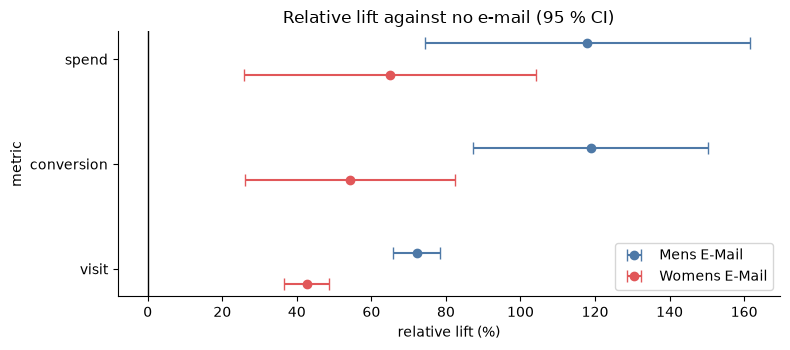

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = {"Mens E-Mail": "#4E79A7", "Womens E-Mail": "#E15759"}
for i, m in enumerate(METRICS):
    for j, t in enumerate(TREATMENTS):
        r = res[(res.arm == t) & (res.metric == m)].iloc[0]
        y = i + (0.15 if j == 0 else -0.15)
        ax.errorbar(r["lift_%"], y, xerr=[[r["lift_%"] - r["lift_lo_%"]], [r["lift_hi_%"] - r["lift_%"]]],
                    fmt="o", color=colors[t], capsize=4, label=t if i == 0 else None)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(3), METRICS)
ax.set(title="Relative lift against no e-mail (95 % CI)", xlabel="relative lift (%)", ylabel="metric")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Both e-mails increase all three metrics, and every CI excludes 0:

- The men's e-mail raises the visit rate from 10.6 % to 18.3 % (+72 %, CI +66 % to +78 %).
- It raises the conversion rate from 0.57 % to 1.25 % (+119 %).
- It raises the mean spend from 0.65 to 1.42 dollars (+118 %, CI +74 % to +162 %).
- The women's e-mail has smaller effects: +43 % on visits, +54 % on conversion and +65 % on spend.

The spend CIs are wide. A 95 % CI from +74 % to +162 % means that the test measures the size of the spend effect
only roughly, although the direction is clear.

### 3. Multiple comparisons

The plan fixes Holm's method for the 6 primary tests. The head-to-head comparison of the two e-mails is a secondary
analysis with its own Holm correction over its 3 metrics.

In [5]:
res["p_holm"] = multipletests(res.p_value, method="holm")[1]
print(res[["arm", "metric", "diff", "p_value", "p_holm"]].to_string(index=False,
      float_format=lambda v: f"{v:.2e}" if abs(v) < 1e-3 else f"{v:.4f}"))
print("primary tests rejected after Holm:", int((res.p_holm < 0.05).sum()), "of", len(res))

h2h = []
for m in METRICS:
    d, se, lo, hi, p = effect(arm["Mens E-Mail"][m].to_numpy(float), arm["Womens E-Mail"][m].to_numpy(float))
    h2h.append([m, d, lo, hi, 100 * d / arm["Womens E-Mail"][m].mean(), p])
h2h = pd.DataFrame(h2h, columns=["metric", "mens_minus_womens", "ci_low", "ci_high", "lift_%", "p_value"])
h2h["p_holm"] = multipletests(h2h.p_value, method="holm")[1]
print("\nhead to head, men's minus women's e-mail:")
print(h2h.to_string(index=False, float_format=lambda v: f"{v:.2e}" if abs(v) < 1e-3 else f"{v:.4f}"))

          arm     metric   diff   p_value    p_holm
  Mens E-Mail      visit 0.0766 2.74e-113 1.64e-112
  Mens E-Mail conversion 0.0068  1.47e-13  5.88e-13
  Mens E-Mail      spend 0.7698  1.16e-07  3.47e-07
Womens E-Mail      visit 0.0452  1.93e-44  9.66e-44
Womens E-Mail conversion 0.0031  1.56e-04  3.12e-04
Womens E-Mail      spend 0.4244    0.0011    0.0011
primary tests rejected after Holm: 6 of 6

head to head, men's minus women's e-mail:
    metric  mens_minus_womens  ci_low  ci_high  lift_%  p_value   p_holm
     visit             0.0314  0.0243   0.0384 20.7109 3.60e-18 1.08e-17
conversion             0.0037  0.0017   0.0056 41.8003 2.06e-04 4.11e-04
     spend             0.3454  0.0326   0.6583 32.0660   0.0305   0.0305


All 6 primary tests stay significant after Holm's correction. The largest adjusted p-value is 0.0011 (women's
e-mail, spend). The effects are large compared with their standard errors, so the correction does not change any
decision.

Head to head, the men's e-mail beats the women's e-mail on visits (+3.1 percentage points, +21 %) and on conversion
(+42 %). On spend the difference is +0.35 dollars per customer (+32 %), with a CI from +0.03 to +0.66 dollars. Its
adjusted p-value is 0.031. This is the weakest result of the analysis: the direction is likely, but the size is
uncertain.

### 4. Ratio metrics with the delta method

*Spend per visit* is $R = \sum y_i / \sum x_i = \bar y / \bar x$, with $y$ = spend and $x$ = visit per customer.
Both the numerator and the denominator are random, so the usual standard error of a mean does not apply. The
**delta method** linearizes the ratio around the means:

$$
\operatorname{Var}(\hat R) \approx \frac{1}{n\,\bar x^2}\left(s_y^2 - 2R\,s_{xy} + R^2 s_x^2\right)
$$

$s_y^2$ and $s_x^2$ are the sample variances and $s_{xy}$ is the sample covariance per customer. The two arms are
independent, so the variance of the difference is the sum of the two variances.

In [6]:
def ratio_delta(y, x):
    # ratio of means and its delta-method standard error
    n, mx = len(y), x.mean()
    r = y.mean() / mx
    cov = np.cov(y, x, ddof=1)
    var = (cov[0, 0] - 2 * r * cov[0, 1] + r**2 * cov[1, 1]) / (n * mx**2)
    return r, np.sqrt(var)

rows = []
for num, label in [("spend", "spend per visit ($)"), ("conversion", "conversion per visit")]:
    r_c, se_c = ratio_delta(arm[CONTROL][num].to_numpy(float), arm[CONTROL].visit.to_numpy(float))
    for t in TREATMENTS:
        r_t, se_t = ratio_delta(arm[t][num].to_numpy(float), arm[t].visit.to_numpy(float))
        d, se = r_t - r_c, np.hypot(se_t, se_c)
        rows.append([label, t, r_c, r_t, d, d - Z * se, d + Z * se, 2 * stats.norm.sf(abs(d / se))])
ratios = pd.DataFrame(rows, columns=["ratio metric", "arm", "control", "treatment", "diff", "ci_low", "ci_high",
                                     "p_value"])
print(ratios.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# bootstrap check of one delta-method SE: spend per visit, men's e-mail
y, x = arm["Mens E-Mail"].spend.to_numpy(float), arm["Mens E-Mail"].visit.to_numpy(float)
boot = []
for _ in range(5):                                         # 5 batches of 200 resamples
    idx = rng.integers(0, len(y), (200, len(y)))
    boot.append(y[idx].sum(1) / x[idx].sum(1))
print(f"\nspend per visit, men's e-mail: delta-method SE {ratio_delta(y, x)[1]:.4f} | "
      f"bootstrap SE (1,000 resamples) {np.std(np.concatenate(boot), ddof=1):.4f}")

        ratio metric           arm  control  treatment   diff  ci_low  ci_high  p_value
 spend per visit ($)   Mens E-Mail   6.1487     7.7842 1.6355 -0.2992   3.5703   0.0976
 spend per visit ($) Womens E-Mail   6.1487     7.1149 0.9662 -0.9909   2.9233   0.3332
conversion per visit   Mens E-Mail   0.0539     0.0686 0.0146  0.0024   0.0269   0.0191
conversion per visit Womens E-Mail   0.0539     0.0584 0.0044 -0.0079   0.0168   0.4806



spend per visit, men's e-mail: delta-method SE 0.6559 | bootstrap SE (1,000 resamples) 0.6181


The delta-method SE (0.656 dollars) and the bootstrap SE (0.618 dollars) agree within about 6 %. Spend has a heavy
tail, so the two estimates differ a little, but the linear approximation is adequate at this sample size.

The ratio metrics tell a different story from the per-customer metrics. A visitor from the men's e-mail spends
7.78 dollars on average, against 6.15 dollars for a visitor in the control group. The difference of +1.64 dollars
has a CI that includes 0 ($p = 0.10$). Conversion per visit rises from 5.4 % to 6.9 % for the men's e-mail
($p = 0.019$). The women's e-mail shows no significant change per visit. So the e-mails mainly bring *more*
visitors; the visitors they bring buy at a similar or slightly higher rate.

A t-test on the visitors only is not correct for this question. The e-mail decides who visits, so the visitors
in the treatment arm are a different set of people from the visitors in the control arm. The comparison is no longer
randomized. Also, the analysis unit (visitor) is then not the randomization unit (customer). The delta method keeps
all randomized customers and gives the SE of the ratio of two means.

### 5. CUPED with `history`

**CUPED** (Controlled-experiment Using Pre-Experiment Data) subtracts the part of the metric that a pre-treatment
covariate $X$ predicts:

$$
Y^{\text{cuped}}_i = Y_i - \theta\,(X_i - \bar X), \qquad \theta = \frac{\operatorname{Cov}(Y, X)}{\operatorname{Var}(X)}, \qquad
\frac{\operatorname{Var}(Y^{\text{cuped}})}{\operatorname{Var}(Y)} = 1 - \rho^2
$$

Measure $X$ before the treatment, so that the treatment cannot change it. Then the adjustment does not bias the
effect, and $\theta$ comes from the pooled data of all arms. $\rho$ is the correlation of $Y$ and $X$.

In [7]:
def cuped(y, x):
    theta = np.cov(y, x, ddof=1)[0, 1] / x.var(ddof=1)
    return y - theta * (x - x.mean()), theta

two = df[df.segment.isin(["Mens E-Mail", CONTROL])]
is_t = (two.segment == "Mens E-Mail").to_numpy()
covs = pd.get_dummies(two[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]],
                      drop_first=True, dtype=float).to_numpy()
rows = []
for m in ["spend", "visit"]:
    y = two[m].to_numpy(float)
    x = two.history.to_numpy(float)
    y_cuped, theta = cuped(y, x)
    # regression adjustment with all pre-treatment covariates (CUPED with several covariates)
    Xc = covs - covs.mean(0)
    beta = np.linalg.lstsq(np.column_stack([np.ones(len(y)), Xc]), y, rcond=None)[0]
    y_reg = y - Xc @ beta[1:]
    for name, v in [("raw", y), ("CUPED history", y_cuped), ("all covariates", y_reg)]:
        d, se, lo, hi, p = effect(v[is_t], v[~is_t])
        rows.append([m, name, theta if name == "CUPED history" else np.nan, d, se, lo, hi,
                     1 - v.var() / y.var()])
cup = pd.DataFrame(rows, columns=["metric", "method", "theta", "diff", "se", "ci_low", "ci_high", "var_reduction"])
cup["var_reduction_%"] = 100 * cup.pop("var_reduction")
print("men's e-mail against control:")
print(cup.to_string(index=False, float_format=lambda v: f"{v:.5f}"))
print(f"\ncorrelation with history: spend {np.corrcoef(two.spend, two.history)[0, 1]:.4f}, "
      f"visit {np.corrcoef(two.visit, two.history)[0, 1]:.4f}")

men's e-mail against control:
metric         method   theta    diff      se  ci_low  ci_high  var_reduction_%
 spend            raw     NaN 0.76983 0.14525 0.48515  1.05451          0.00000
 spend  CUPED history 0.00122 0.76744 0.14522 0.48282  1.05205          0.04378
 spend all covariates     NaN 0.76676 0.14515 0.48227  1.05125          0.13051
 visit            raw     NaN 0.07659 0.00339 0.06995  0.08323          0.00000
 visit  CUPED history 0.00009 0.07641 0.00338 0.06979  0.08303          0.44439
 visit all covariates     NaN 0.07605 0.00334 0.06951  0.08259          2.90633

correlation with history: spend 0.0209, visit 0.0667


CUPED gives almost nothing here. The correlation of spend with `history` is only 0.021, so the variance falls by
$\rho^2 = 0.04$ %. For visit the correlation is 0.067, and the variance falls by 0.44 %. All pre-treatment covariates
together reduce the variance of visit by 2.9 % and of spend by 0.13 %. The effect estimates barely move,
which confirms that the adjustment does not bias them.

This is an honest negative result. CUPED works when the pre-period metric is the *same* metric as the outcome, for
example spend in the two weeks before the test. Then $\rho$ is often 0.5 or more, and the variance falls by 25 % or
more. `history` is a yearly total with a different shape from a two-week spend that is 0 for 99 % of customers.
For the next test, log the same metric for a pre-period window.

### 6. Pre-planned segment: last year's product category

The plan names one segment: the category that the customer bought last year. `mens` and `womens` are 0/1 flags, and
every customer has at least one, so there are three segments. The **interaction test** asks if the effect differs
between two segments:

$$
z = \frac{\hat\delta_1 - \hat\delta_2}{\sqrt{SE_1^2 + SE_2^2}}
$$

In [8]:
df["bought"] = np.select([(df.mens == 1) & (df.womens == 0), (df.mens == 0) & (df.womens == 1)],
                         ["men's only", "women's only"], "both")
SEGS = ["men's only", "women's only", "both"]
rows = []
for s in SEGS:
    g = df[df.bought == s]
    for t in TREATMENTS:
        for m in ["visit", "spend"]:
            d, se, lo, hi, p = effect(g.loc[g.segment == t, m].to_numpy(float), g.loc[g.segment == CONTROL, m].to_numpy(float))
            rows.append([s, (g.segment == CONTROL).sum(), t, m, d, se, lo, hi, p])
seg = pd.DataFrame(rows, columns=["bought", "n_control", "arm", "metric", "diff", "se", "ci_low", "ci_high", "p_value"])
print(seg.drop(columns="se").to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print("\ninteraction tests, men's only vs women's only:")
for t in TREATMENTS:
    for m in ["visit", "spend"]:
        a = seg[(seg.bought == "men's only") & (seg.arm == t) & (seg.metric == m)].iloc[0]
        b = seg[(seg.bought == "women's only") & (seg.arm == t) & (seg.metric == m)].iloc[0]
        z = (a["diff"] - b["diff"]) / np.hypot(a.se, b.se)
        print(f"  {t:>13} {m:>5}: effect {a['diff']:+.4f} vs {b['diff']:+.4f}, z = {z:+.2f}, "
              f"p = {2 * stats.norm.sf(abs(z)):.4f}")

      bought  n_control           arm metric   diff  ci_low  ci_high  p_value
  men's only       9638   Mens E-Mail  visit 0.0692  0.0596   0.0788   0.0000
  men's only       9638   Mens E-Mail  spend 0.6827  0.2472   1.1183   0.0021
  men's only       9638 Womens E-Mail  visit 0.0111  0.0024   0.0197   0.0123
  men's only       9638 Womens E-Mail  spend 0.2784 -0.1236   0.6803   0.1747
women's only       9519   Mens E-Mail  visit 0.0706  0.0611   0.0801   0.0000
women's only       9519   Mens E-Mail  spend 0.6157  0.2697   0.9618   0.0005
women's only       9519 Womens E-Mail  visit 0.0740  0.0644   0.0835   0.0000
women's only       9519 Womens E-Mail  spend 0.6316  0.2951   0.9682   0.0002
        both       2149   Mens E-Mail  visit 0.1344  0.1091   0.1598   0.0000
        both       2149   Mens E-Mail  spend 1.8250  0.4902   3.1598   0.0074
        both       2149 Womens E-Mail  visit 0.0711  0.0465   0.0957   0.0000
        both       2149 Womens E-Mail  spend 0.1619 -0.8133   1.

    Mens E-Mail visit: effect +0.0692 vs +0.0706, z = -0.21, p = 0.8365
    Mens E-Mail spend: effect +0.6827 vs +0.6157, z = +0.24, p = 0.8134
  Womens E-Mail visit: effect +0.0111 vs +0.0740, z = -9.56, p = 0.0000
  Womens E-Mail spend: effect +0.2784 vs +0.6316, z = -1.32, p = 0.1865


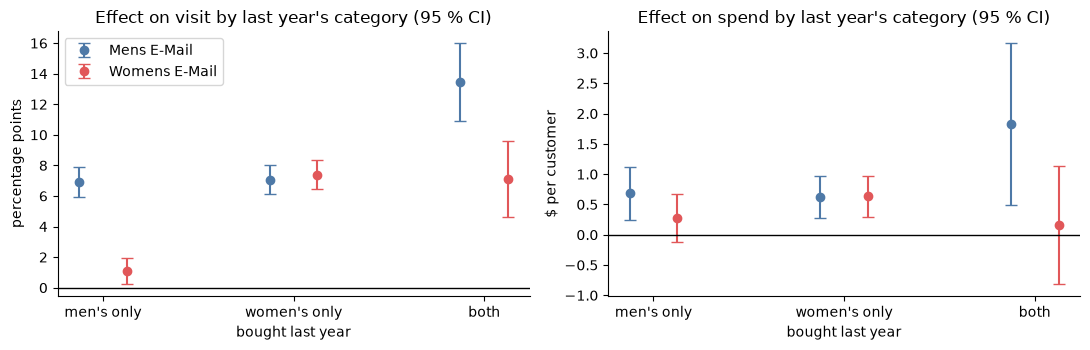

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for k, m in enumerate(["visit", "spend"]):
    for j, t in enumerate(TREATMENTS):
        s_ = seg[(seg.arm == t) & (seg.metric == m)]
        ax[k].errorbar(np.arange(3) + (j - 0.5) * 0.25, s_["diff"] * (100 if m == "visit" else 1),
                       yerr=Z * s_.se * (100 if m == "visit" else 1), fmt="o", capsize=4, color=colors[t], label=t)
    ax[k].axhline(0, color="black", lw=1)
    ax[k].set_xticks(range(3), SEGS)
    ax[k].set(title=f"Effect on {m} by last year's category (95 % CI)", xlabel="bought last year",
              ylabel="percentage points" if m == "visit" else "$ per customer")
ax[0].legend()
plt.tight_layout(); plt.show()

The segment result is clear for visits:

- Men's-only buyers: the men's e-mail adds +6.9 percentage points of visits, the women's e-mail only +1.1.
- Women's-only buyers: the two e-mails are close, +7.1 and +7.4 points.
- Buyers of both categories (the smallest segment, 2,149 control customers): +13.4 and +7.1 points.

The interaction tests confirm the pattern. The women's e-mail works much better for women's-only buyers than for
men's-only buyers ($z = -9.6$, $p < 10^{-20}$). The men's e-mail has the same visit effect in both segments
($p = 0.84$).

For spend, the segment CIs are wide. No interaction test is significant at 5 %: the women's e-mail spend effect is
+0.28 against +0.63 dollars ($p = 0.19$). The point estimates follow the visit pattern, but these segment sizes cannot
resolve spend differences between segments.

**Subgroup fishing** means to test many segments after the test and to report the ones with $p < 0.05$. With
7 covariates and their levels, an analyst can form dozens of segments. Some of them will show a "significant"
effect by chance alone (Lesson 01, Section 8). This analysis tests one pre-planned segment; every other segment
result is a hypothesis for the next test, not a finding.

### 7. Plan the follow-up test

The follow-up compares the men's against the women's e-mail on spend, with the difference of this test as the MDE.

In [10]:
y_m, y_w = arm["Mens E-Mail"].spend.to_numpy(float), arm["Womens E-Mail"].spend.to_numpy(float)
mde = y_m.mean() - y_w.mean()
sd = np.sqrt((y_m.var(ddof=1) + y_w.var(ddof=1)) / 2)
n_arm = TTestIndPower().solve_power(effect_size=mde / sd, alpha=0.05, power=0.8)
print(f"MDE {mde:.3f} $ per customer, pooled sd {sd:.2f} $, Cohen's d {mde / sd:.4f}")
print(f"n per arm for 80 % power: {np.ceil(n_arm):,.0f} (this test had about {len(y_m):,} per arm)")
power_now = TTestIndPower().power(effect_size=mde / sd, nobs1=len(y_m), alpha=0.05)
print(f"power of this test for the same difference: {power_now:.2f}")

MDE 0.345 $ per customer, pooled sd 16.49 $, Cohen's d 0.0209
n per arm for 80 % power: 35,769 (this test had about 21,307 per arm)
power of this test for the same difference: 0.58


The follow-up needs about 35,800 customers per arm, 1.7 times the size of this test. This test had a power of only
0.58 for its own observed difference. That agrees with the weak head-to-head result in Task 3. The observed
difference may also be larger than the true one, because a significant result from a low-power test tends to
overestimate the effect.

The team wants to check the p-value every day. A fixed-horizon test assumes one look at the planned $n$. With daily
looks, the chance that the p-value falls below 0.05 at least once is much larger than 5 %, also without any effect.
Use a sequential test such as the mSPRT (Lesson 07), or fix the sample size and look once.

### 8. Recommendation

Send the men's e-mail to all customers. The test is valid: SRM $p = 0.90$ and all $|\text{SMD}| < 0.02$. In two weeks, the men's
e-mail raises mean spend from 0.65 to 1.42 dollars per customer. The 95 % CI of the +0.77 dollars is +0.49 to +1.06.
That is about 770 dollars more per 1,000 e-mails.

It beats the women's e-mail on visits and conversion. It also beats it by 0.35 dollars on spend, but this spend
difference is uncertain (CI +0.03 to +0.66). In the pre-planned segment, the men's
e-mail is at least as good as the women's e-mail for every group of buyers. Only for women's-only buyers do the two
e-mails perform the same, so the team can choose either e-mail for them. The extra spend comes mainly from more
visitors, not from more spend per visitor. Confirm the spend gap in a follow-up test with about 35,800 customers per
arm.

## Submission Checklist

- [ ] The SRM test and the covariate balance come before any effect estimate.
- [ ] Every effect has a 95 % CI, not only a p-value.
- [ ] You choose the multiple comparison method before you read the results, and you apply it to all primary tests.
- [ ] The ratio metric uses the delta method on all randomized customers, not a t-test on visitors only.
- [ ] CUPED uses only pre-treatment data. The notebook reports the real variance reduction, also if it is small.
- [ ] The segment analysis uses only the pre-planned segment, and it includes an interaction test.
- [ ] The recommendation states numbers and their uncertainty.